In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/eslamfawzysayed/hydrochare111/final_dataset.csv


In [2]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')

In [3]:
import pandas as pd

# قراءة ملف CSV الجديد
df = pd.read_csv(
    '/kaggle/input/datasets/eslamfawzysayed/hydrochare111/final_dataset.csv'
)

# عرض أسماء الأعمدة للتحقق
print("Column names:", df.columns.tolist())
print("\nFirst 5 rows of data:")
df.head()

Column names: ['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 'water Content', 'T( °C)', 'Reaction Time (min)', 'yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)', 'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)', 'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']

First 5 rows of data:


,C%,H%,N%,S%,O%,Ash%,Volatile matter%,Fixed carbon%,HHV (MJ/Kg),DM(%),...,Nc(%),Sc(%),Oc(%),HHVc (MJ/Kg),EY(%),ED(%),CR(%),HC- Volatile matter%,HC- Fixed carbon%,HC- Ash(%)
0,34.78,3.93,5.04,1.15,20.32,31.77,55.81,7.76,16.61,4.5,...,5.11,1.07,15.46,16.97,70.291150,1.021674,70.283611,49.65,9.16,38.63
1,34.78,3.93,5.04,1.15,20.32,31.77,55.81,7.76,16.61,4.5,...,2.01,1.09,14.66,14.33,63.324624,0.862733,70.086659,43.82,9.05,45.11
2,34.78,3.93,5.04,1.15,20.32,31.77,55.81,7.76,16.61,4.5,...,4.23,1.19,14.78,17.80,60.869356,1.071644,62.107648,51.11,9.21,36.88
3,33.30,4.60,4.00,1.20,20.30,36.70,51.80,9.34,14.40,2.5,...,1.90,1.20,9.40,15.40,65.900000,0.970000,65.549550,41.90,4.90,51.20
4,33.30,4.60,4.00,1.20,20.30,36.70,51.80,9.34,14.40,5.0,...,2.10,0.80,10.30,15.30,69.800000,0.970000,69.900000,41.70,6.50,50.00


In [4]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 'water Content', 'T( °C)', 'Reaction Time (min)', 'yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)', 'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)', 'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']


In [7]:
import pandas as pd

# Read CSV file
df = pd.read_csv(
    '/kaggle/input/datasets/eslamfawzysayed/hydrochare111/final_dataset.csv'
)

# Check if there are any object columns
object_columns = df.select_dtypes(include=['object']).columns

if len(object_columns) > 0:
    # Display object columns statistics
    with pd.option_context('display.max_columns', None):
        print(df.describe(include='object'))
else:
    print("No object (string) columns found in the dataset.")
    print("\nColumn data types:")
    print(df.dtypes)
    
    # Display all columns statistics instead
    print("\nShowing statistics for all numeric columns:")
    with pd.option_context('display.max_columns', None):
        print(df.describe())

No object (string) columns found in the dataset.

Column data types:
C%                      float64
H%                      float64
N%                      float64
S%                      float64
O%                      float64
Ash%                    float64
Volatile matter%        float64
Fixed carbon%           float64
HHV (MJ/Kg)             float64
DM(%)                   float64
water Content           float64
T( °C)                    int64
Reaction Time (min)       int64
yield(%)                float64
Cc (%)                  float64
Hc(%)                   float64
Nc(%)                   float64
Sc(%)                   float64
Oc(%)                   float64
HHVc (MJ/Kg)            float64
EY(%)                   float64
ED(%)                   float64
CR(%)                   float64
HC- Volatile matter%    float64
HC- Fixed carbon%       float64
HC- Ash(%)              float64
dtype: object

Showing statistics for all numeric columns:
               C%          H%          N

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271 entries, 0 to 270
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   C%                    271 non-null    float64
 1   H%                    271 non-null    float64
 2   N%                    271 non-null    float64
 3   S%                    271 non-null    float64
 4   O%                    271 non-null    float64
 5   Ash%                  271 non-null    float64
 6   Volatile matter%      271 non-null    float64
 7   Fixed carbon%         271 non-null    float64
 8   HHV (MJ/Kg)           271 non-null    float64
 9   DM(%)                 271 non-null    float64
 10  water Content         271 non-null    float64
 11  T( °C)                271 non-null    int64  
 12  Reaction Time (min)   271 non-null    int64  
 13  yield(%)              271 non-null    float64
 14  Cc (%)                271 non-null    float64
 15  Hc(%)                 2

📊 Data loaded successfully (After Outlier Capping)!
df_filled shape: (271, 26)

ℹ️ Column 'Type of liquide' not found in dataset (no action needed)
Current shape: (271, 26)

✅ Column 'water Content' renamed to 'water Content (%)'

✅ Number of independent variables: 13
✅ Number of dependent variables: 13

📊 Final data shape after removing NaN: (271, 26)

📊 Correlation matrix (Spearman) - After Outlier Capping:
Matrix size: (26, 26)

✅ Figure saved as 'spearman_correlation_matrix_capped.png' at 600 DPI


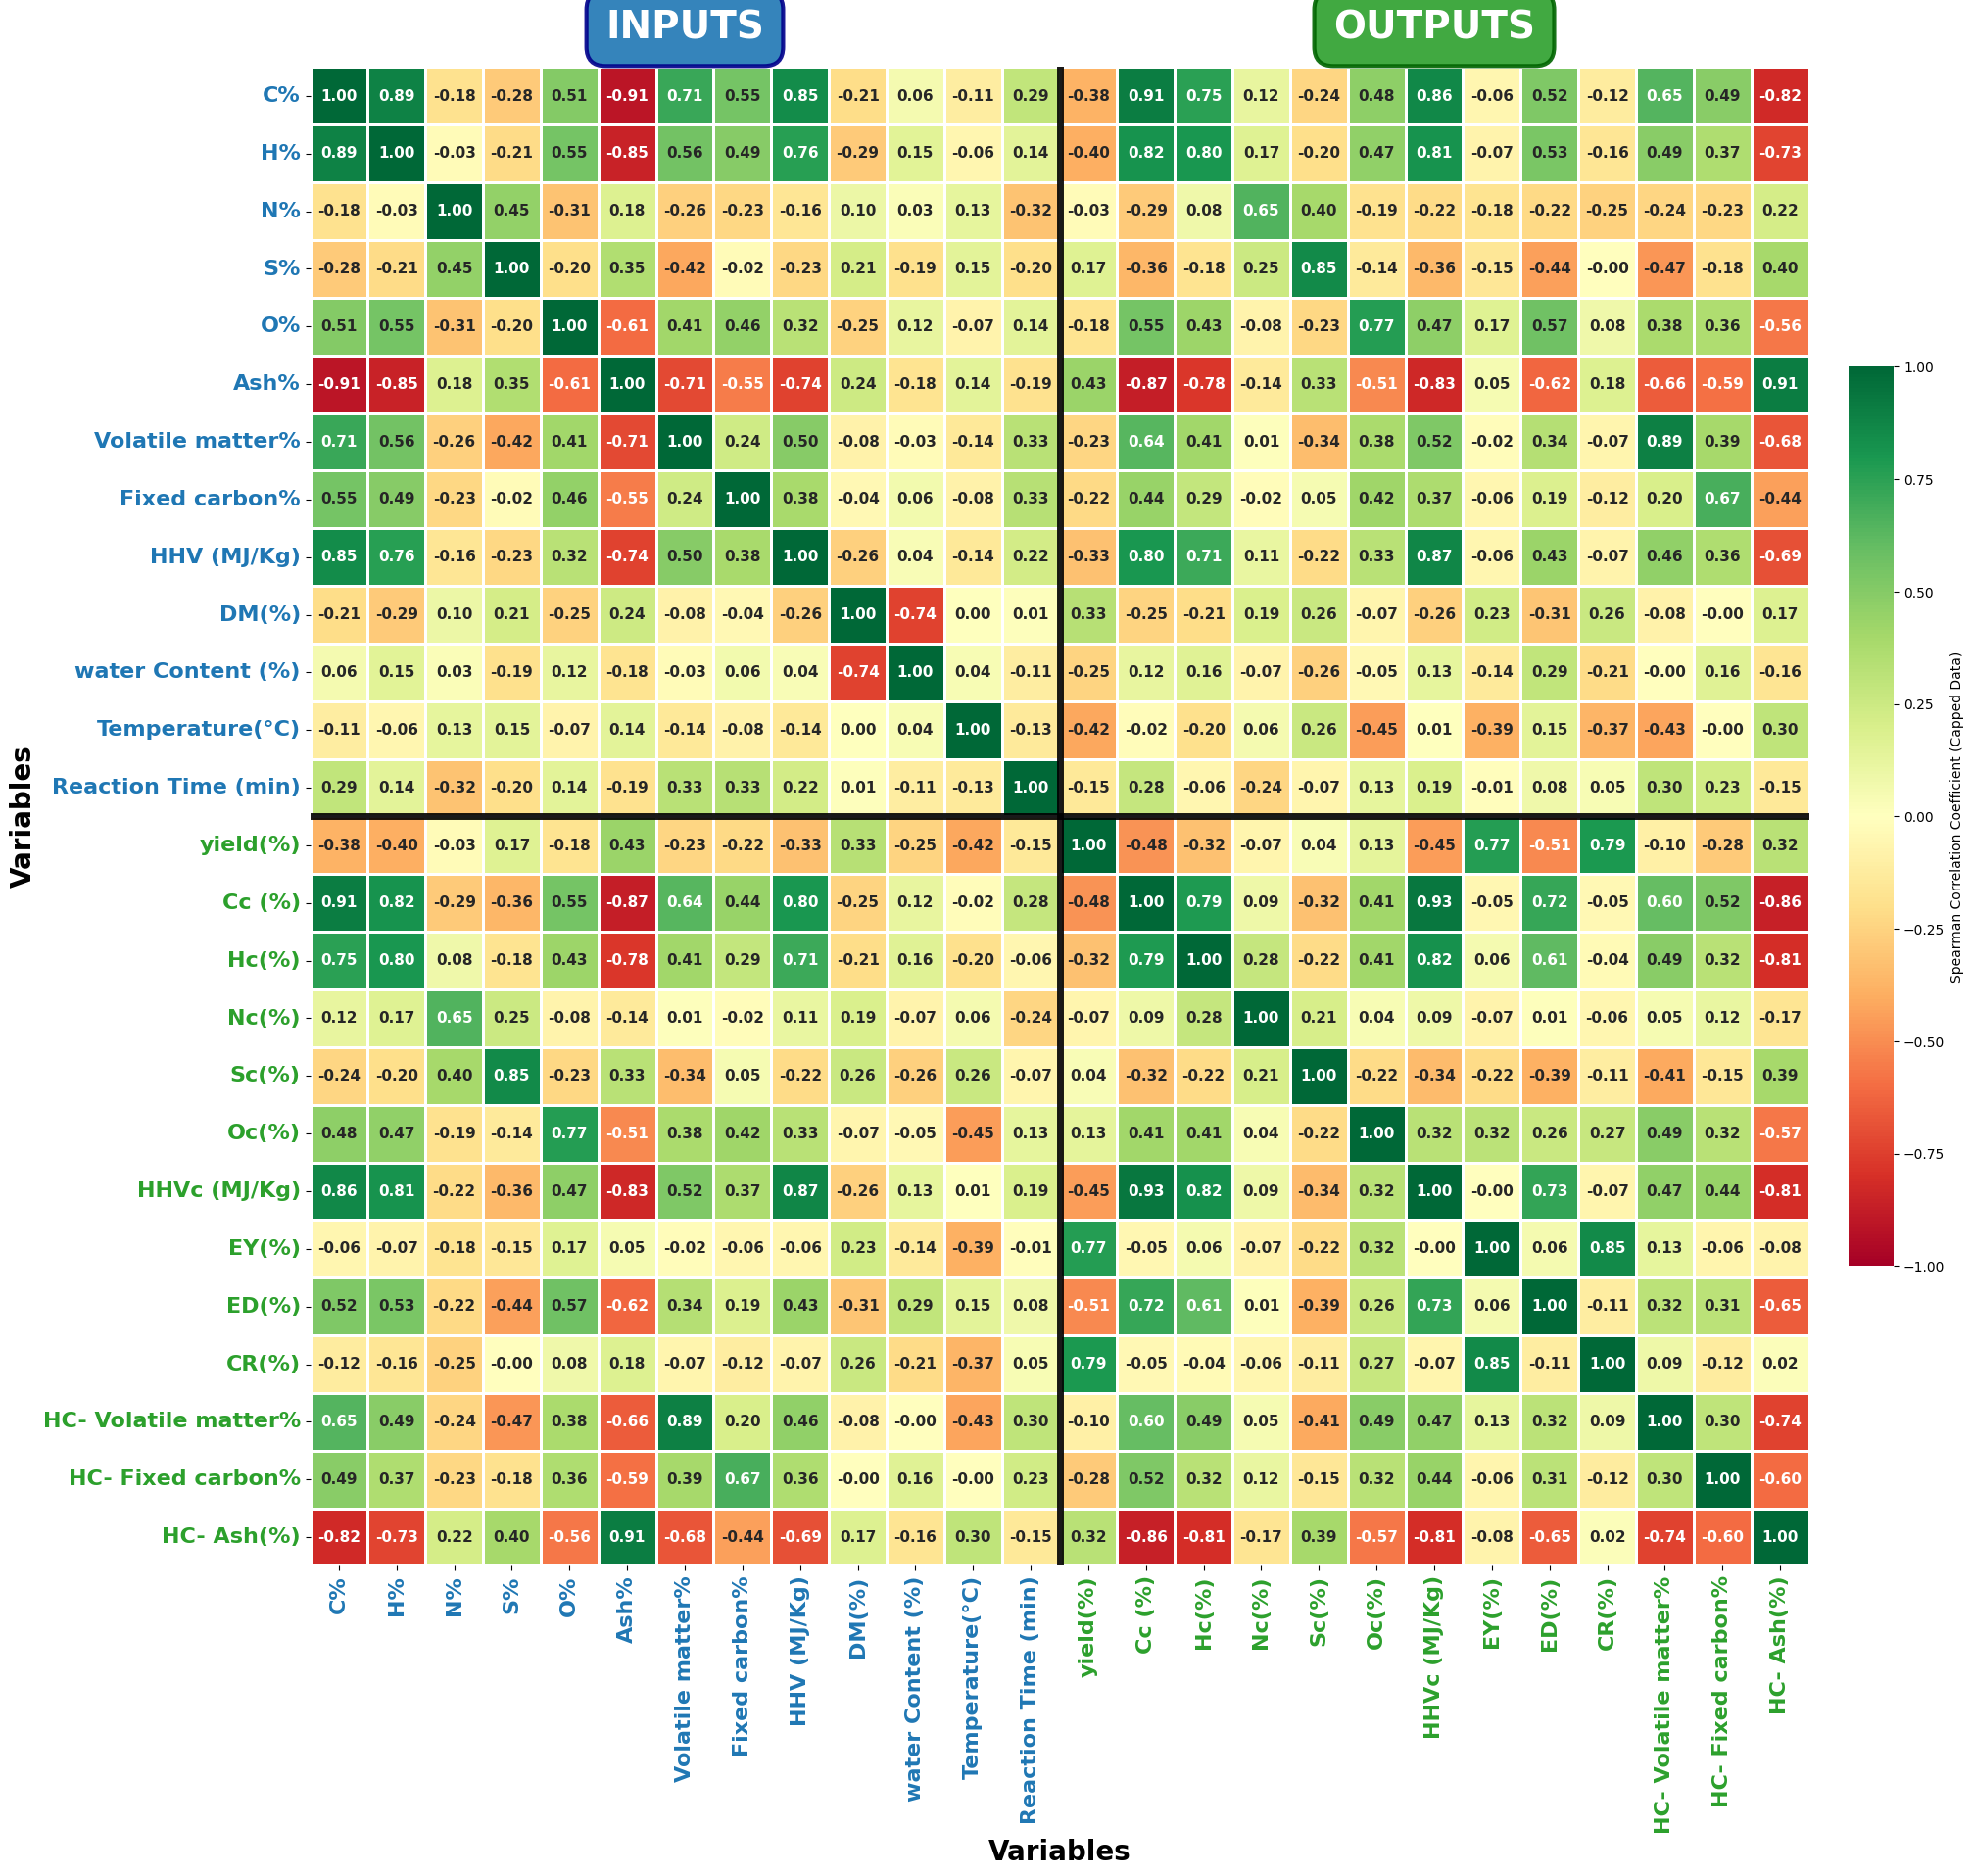


🔍 Most important correlations between inputs and outputs (Capped Data):

✅ Top 10 positive correlations:
  HC- Ash(%) → Ash%: 0.913
  Cc (%) → C%: 0.910
  HC- Volatile matter% → Volatile matter%: 0.891
  HHVc (MJ/Kg) → HHV (MJ/Kg): 0.868
  HHVc (MJ/Kg) → C%: 0.860
  Sc(%) → S%: 0.852
  Cc (%) → H%: 0.815
  HHVc (MJ/Kg) → H%: 0.813
  Hc(%) → H%: 0.803
  Cc (%) → HHV (MJ/Kg): 0.801

❌ Top 10 negative correlations:
  Cc (%) → Ash%: -0.870
  HHVc (MJ/Kg) → Ash%: -0.834
  HC- Ash(%) → C%: -0.823
  Hc(%) → Ash%: -0.776
  HC- Ash(%) → H%: -0.728
  HC- Ash(%) → HHV (MJ/Kg): -0.688
  HC- Ash(%) → Volatile matter%: -0.675
  HC- Volatile matter% → Ash%: -0.655
  ED(%) → Ash%: -0.622
  HC- Fixed carbon% → Ash%: -0.587

✅ Figure saved as 'key_correlations_capped.png' at 600 DPI


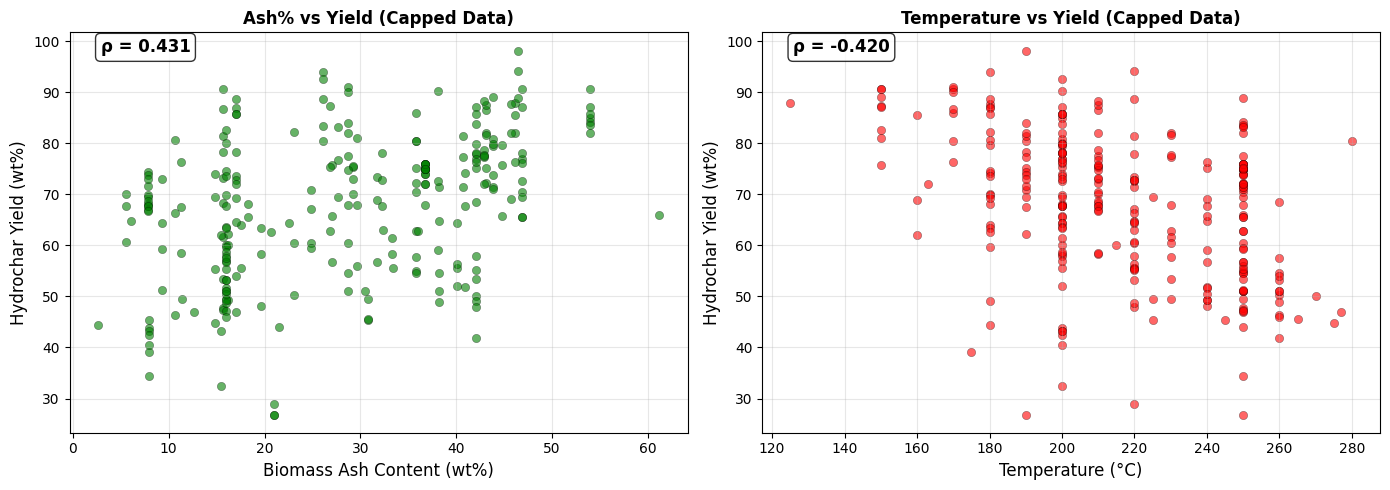


✅ Correlation matrix saved to 'spearman_correlation_matrix_capped.xlsx'

✅ Correlation analysis completed successfully on CAPPED DATA!


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt
plt.style.use('default')
# ============================================
# 1. Load CAPPED data (after outlier capping)
# ============================================
df_filled = pd.read_excel('df_capped_outliers.xlsx')

print("=" * 70)
print("📊 Data loaded successfully (After Outlier Capping)!")
print(f"df_filled shape: {df_filled.shape}")

# ============================================
# 2. Check if 'Type of liquide' column exists and delete if present
# ============================================
if 'Type of liquide' in df_filled.columns:
    df_filled = df_filled.drop('Type of liquide', axis=1)
    print("\n✅ Column 'Type of liquide' has been deleted")
else:
    print("\nℹ️ Column 'Type of liquide' not found in dataset (no action needed)")

print(f"Current shape: {df_filled.shape}")

# ============================================
# 3. Rename 'water Content' to 'water Content (%)' if needed
# ============================================
if 'water Content' in df_filled.columns and 'water Content (%)' not in df_filled.columns:
    df_filled = df_filled.rename(columns={'water Content': 'water Content (%)'})
    print("\n✅ Column 'water Content' renamed to 'water Content (%)'")

# ============================================
# 4. Rename 'T( °C)' to 'Temperature(°C)' if needed
# ============================================
if 'T( °C)' in df_filled.columns and 'Temperature(°C)' not in df_filled.columns:
    df_filled = df_filled.rename(columns={'T( °C)': 'Temperature(°C)'})
    print("\n✅ Column 'T( °C)' renamed to 'Temperature(°C)'")

# ============================================
# 5. Select ALL variables with correct column names
# ============================================

# Independent variables (Inputs)
input_features = [
    'C%',                    # Carbon content
    'H%',                    # Hydrogen content
    'N%',                    # Nitrogen content
    'S%',                    # Sulfur content
    'O%',                    # Oxygen content
    'Ash%',                  # Ash content
    'Volatile matter%',      # Volatile matter
    'Fixed carbon%',         # Fixed carbon
    'HHV (MJ/Kg)',          # Higher Heating Value
    'DM(%)',                # Dry Matter
    'water Content (%)',     # Water content (updated with %)
    'Temperature(°C)',       # Temperature
    'Reaction Time (min)'    # Reaction time
]

# Dependent variables (Outputs)
output_features = [
    'yield(%)',              # Hydrochar yield
    'Cc (%)',               # Carbon in hydrochar
    'Hc(%)',                # Hydrogen in hydrochar
    'Nc(%)',                # Nitrogen in hydrochar
    'Sc(%)',                # Sulfur in hydrochar
    'Oc(%)',                # Oxygen in hydrochar
    'HHVc (MJ/Kg)',         # Higher Heating Value of hydrochar
    'EY(%)',                # Energy Yield
    'ED(%)',                # Energy Densification
    'CR(%)',                # Carbon Recovery
    'HC- Volatile matter%', # Volatile matter in hydrochar
    'HC- Fixed carbon%',    # Fixed carbon in hydrochar
    'HC- Ash(%)'            # Ash in hydrochar
]

# ============================================
# 6. Check if columns exist and are numeric
# ============================================
existing_inputs = [col for col in input_features if col in df_filled.columns]
existing_outputs = [col for col in output_features if col in df_filled.columns]

# Ensure all columns are numeric
for col in existing_inputs + existing_outputs:
    if df_filled[col].dtype == 'object':
        print(f"⚠️ Converting column '{col}' to numeric...")
        df_filled[col] = pd.to_numeric(df_filled[col], errors='coerce')

print(f"\n✅ Number of independent variables: {len(existing_inputs)}")
print(f"✅ Number of dependent variables: {len(existing_outputs)}")

# ============================================
# 7. Create DataFrames for inputs and outputs
# ============================================
X = df_filled[existing_inputs].copy()
Y = df_filled[existing_outputs].copy()

# Remove any rows with NaN
combined = pd.concat([X, Y], axis=1)
combined = combined.dropna()
X = combined[existing_inputs]
Y = combined[existing_outputs]

# Combine for correlation
correlation_data = pd.concat([X, Y], axis=1)

print(f"\n📊 Final data shape after removing NaN: {correlation_data.shape}")

# ============================================
# 8. Calculate correlation matrix (Spearman)
# ============================================
corr_matrix = correlation_data.corr(method='spearman')

print("\n" + "=" * 70)
print("📊 Correlation matrix (Spearman) - After Outlier Capping:")
print("=" * 70)
print(f"Matrix size: {corr_matrix.shape}")

# ============================================
# 9. Plot with Input/Output separation using lines and labels
# ============================================

# 9.1 Create colored labels for inputs and outputs
input_labels = [f'{col}' for col in existing_inputs]
output_labels = [f'{col}' for col in existing_outputs]
all_labels = input_labels + output_labels

# Create color lists for x and y tick labels
input_colors = ['#1f77b4'] * len(existing_inputs)  # Blue for inputs
output_colors = ['#2ca02c'] * len(existing_outputs)  # Green for outputs
tick_colors = input_colors + output_colors

# 9.2 Setup figure with larger size
fig, ax = plt.subplots(figsize=(24, 18))

# 9.3 Draw heatmap with larger font
heatmap = sns.heatmap(
    corr_matrix,
    annot=True,           # Show numbers
    fmt='.2f',            # Two decimal places
    cmap='RdYlGn',        # Red-Yellow-Green
    center=0,             # Center at zero
    square=True,          # Square cells
    linewidths=1.0,       # Thicker lines between cells
    cbar_kws={
        'shrink': 0.6,
        'label': 'Spearman Correlation Coefficient (Capped Data)',
        'pad': 0.02
    },
    annot_kws={'size': 11, 'fontweight': 'bold'},
    vmin=-1, vmax=1,
    ax=ax,
    xticklabels=all_labels,
    yticklabels=all_labels
)

# 9.4 Format figure with larger fonts - REMOVED TITLE
# No title at the top

# 9.5 Improve axes with larger font
ax.set_xlabel('Variables', fontsize=20, fontweight='bold')
ax.set_ylabel('Variables', fontsize=20, fontweight='bold')

# 9.6 Rotate axis labels with MUCH BIGGER font and colors
# Set x-tick labels with colors
for tick_label, color in zip(ax.get_xticklabels(), tick_colors):
    tick_label.set_color(color)
    tick_label.set_fontsize(16)
    tick_label.set_fontweight('bold')
    tick_label.set_rotation(90)
    tick_label.set_ha('center')

# Set y-tick labels with colors
for tick_label, color in zip(ax.get_yticklabels(), tick_colors):
    tick_label.set_color(color)
    tick_label.set_fontsize(16)
    tick_label.set_fontweight('bold')
    tick_label.set_rotation(0)

# 9.7 Add colored separator lines between Input and Output
n_inputs = len(existing_inputs)
n_outputs = len(existing_outputs)
total = n_inputs + n_outputs

# Draw vertical line between Input and Output columns (at x = n_inputs)
ax.axvline(x=n_inputs, color='black', linewidth=5, linestyle='-', alpha=0.9)
# Draw horizontal line between Input and Output rows (at y = n_inputs)
ax.axhline(y=n_inputs, color='black', linewidth=5, linestyle='-', alpha=0.9)

# 9.8 Add "INPUTS" label above the input columns with BLUE color
ax.text(n_inputs/2, -0.35, 'INPUTS', 
        transform=ax.transData, 
        fontsize=28, fontweight='bold', 
        ha='center', va='bottom',
        color='white',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#1f77b4', edgecolor='darkblue', alpha=0.9, linewidth=3))

# Add "OUTPUTS" label above the output columns with GREEN color
ax.text(n_inputs + n_outputs/2, -0.35, 'OUTPUTS', 
        transform=ax.transData, 
        fontsize=28, fontweight='bold', 
        ha='center', va='bottom',
        color='white',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#2ca02c', edgecolor='darkgreen', alpha=0.9, linewidth=3))

# 9.9 Add colored backgrounds for different regions
ylim = ax.get_ylim()

# Input-Input region (top-left) - BLUE background
ax.axhspan(ylim[1]-n_inputs, ylim[1], xmin=0, xmax=n_inputs/total,
           color='#1f77b4', alpha=0.08, zorder=0)
# Output-Output region (bottom-right) - GREEN background
ax.axhspan(ylim[0], ylim[0]+n_outputs, xmin=n_inputs/total, xmax=1,
           color='#2ca02c', alpha=0.08, zorder=0)

# 9.10 Adjust layout with more space
plt.subplots_adjust(top=0.95, bottom=0.10, left=0.10, right=0.95)

# 9.11 Save figure with high quality
plt.savefig('spearman_correlation_matrix_capped.png', dpi=600, bbox_inches='tight')
print("\n✅ Figure saved as 'spearman_correlation_matrix_capped.png' at 600 DPI")

# ============================================
# 10. Show figure
# ============================================
plt.show()

# ============================================
# 11. Extract most important correlations
# ============================================
print("\n" + "=" * 70)
print("🔍 Most important correlations between inputs and outputs (Capped Data):")
print("=" * 70)

# Correlations between inputs and outputs
input_output_corr = corr_matrix.loc[existing_inputs, existing_outputs]

# Top 10 positive correlations
top_positive = input_output_corr.unstack().sort_values(ascending=False).head(10)
print("\n✅ Top 10 positive correlations:")
for (inp, out), val in top_positive.items():
    print(f"  {inp} → {out}: {val:.3f}")

# Top 10 negative correlations
top_negative = input_output_corr.unstack().sort_values(ascending=True).head(10)
print("\n❌ Top 10 negative correlations:")
for (inp, out), val in top_negative.items():
    print(f"  {inp} → {out}: {val:.3f}")

# ============================================
# 12. Plot specific correlations (Capped Data)
# ============================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 12.1 Ash% vs Yield
if 'Ash%' in df_filled.columns and 'yield(%)' in df_filled.columns:
    axes[0].scatter(
        df_filled['Ash%'], 
        df_filled['yield(%)'],
        alpha=0.6,
        c='green',
        edgecolors='black',
        linewidth=0.3
    )
    axes[0].set_xlabel('Biomass Ash Content (wt%)', fontsize=12)
    axes[0].set_ylabel('Hydrochar Yield (wt%)', fontsize=12)
    axes[0].set_title('Ash% vs Yield (Capped Data)', fontsize=12, fontweight='bold')
    axes[0].grid(True, alpha=0.3)
    
    corr = df_filled['Ash%'].corr(df_filled['yield(%)'], method='spearman')
    axes[0].text(
        0.05, 0.95, f'ρ = {corr:.3f}',
        transform=axes[0].transAxes,
        fontsize=12,
        fontweight='bold',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
    )

# 12.2 Temperature vs Yield
if 'Temperature(°C)' in df_filled.columns and 'yield(%)' in df_filled.columns:
    axes[1].scatter(
        df_filled['Temperature(°C)'], 
        df_filled['yield(%)'],
        alpha=0.6,
        c='red',
        edgecolors='black',
        linewidth=0.3
    )
    axes[1].set_xlabel('Temperature (°C)', fontsize=12)
    axes[1].set_ylabel('Hydrochar Yield (wt%)', fontsize=12)
    axes[1].set_title('Temperature vs Yield (Capped Data)', fontsize=12, fontweight='bold')
    axes[1].grid(True, alpha=0.3)
    
    corr = df_filled['Temperature(°C)'].corr(df_filled['yield(%)'], method='spearman')
    axes[1].text(
        0.05, 0.95, f'ρ = {corr:.3f}',
        transform=axes[1].transAxes,
        fontsize=12,
        fontweight='bold',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
    )

plt.tight_layout()
plt.savefig('key_correlations_capped.png', dpi=600, bbox_inches='tight')
print("\n✅ Figure saved as 'key_correlations_capped.png' at 600 DPI")
plt.show()

# ============================================
# 13. Save correlation matrix
# ============================================
corr_matrix.to_excel('spearman_correlation_matrix_capped.xlsx')
print("\n✅ Correlation matrix saved to 'spearman_correlation_matrix_capped.xlsx'")

print("\n" + "=" * 70)
print("✅ Correlation analysis completed successfully on CAPPED DATA!")
print("=" * 70)